# The window integral and the height, all channels summed, with the cuts of the small, quiet events (-82 V, DCRC1pB trigger)

*Draft prepared with Claude Code for A. Villano, 2026-11-02.*

The events are selected with the same cuts as `positions-small-quiet-82v.ipynb`:

* real triggers (`Unknown`), with the series `07221113_1159` left out;
* `bstd` in every channel below twice the median of the random triggers;
* no channel above 5 % of its saturated height: **switched off since 2026-11-03** (`SIZE_CUT = False` in the cut cell), so events of every size are kept;
* six 20 % times, all within 60 us of their median;
* **the blob is a tight circle of 4 us** around (`xdel`, `ydel`) = (22, 2) us, in the re-centred plane of that notebook (since 2026-11-03; it was 10 us). The comparison, *outside the blob*, is the events **outside the old 10 us circle**, so the shoulder of the blob, between 4 and 10 us, is in neither set.

**The cuts use the quantities of `r76-82v-dcrc1pb.dataset.toml`**, the dataset that notebook used, so with `SIZE_CUT = True` they select the same 16,228 events. The cut quantities come from that notebook's cache in `~/goldsluice-output` if it is there. **The integral comes from the new dataset, `r76-82V-window-integral.dataset.toml`.** It holds the `window_integral` of every channel over samples 450 to 950, which runs from 40 us before the trigger to 360 us after it. That integral is taken after `subtract_line` has subtracted a straight line from each trace. **The line is fitted to the whole trace (samples 10 to 4095), with the pulse in it**, unlike the notebook's fit, which left the pulse out. For these small pulses, which last about 200 us, the two agree to about 3 %.

Both datasets hold the same 436 dumps, read in the same order, so the rows correspond one to one. The first cell checks this on `series`, `dump` and `event` before anything is used. Run with the `darkmatter_cli_env` kernel.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyarrow.compute as pc
import pyarrow.parquet as pq
from matplotlib import colors

from goldpan.dataset import Dataset

LETTERS = "ABCDEF"
_here = Path.cwd().resolve()
PROCESSING = next(p / "data_analysis" / "R76" / "processing" for p in [_here, *_here.parents] if (p / "data_analysis" / "R76" / "processing").is_dir())
OUT_CUTS = Path(Dataset.open(PROCESSING / "r76-82v-dcrc1pb.dataset.toml").spec.output)          # the cuts, as in positions-small-quiet-82v
OUT_WIN = Path(Dataset.open(PROCESSING / "r76-82V-window-integral.dataset.toml").spec.output)   # the window integral
PRE = json.loads((OUT_CUTS / "_goldpan.json").read_text(encoding="utf-8"))["streams"]["NAI-S2"]["detector"]["segments"][0]["pretrigger_samples"]
CACHE = Path.home() / "goldsluice-output" / f"relcal-positions-small-82v-p{PRE}.npz"             # the cache of positions-small-quiet-82v
WCACHE = Path.home() / "goldsluice-output" / "relcal-window-integral-82v.npz"                    # this notebook's: the window integral and the row check

def field(tab, k, name):
    # one quantity of one channel: the channel is a struct column of the Parquet file
    return pc.struct_field(tab[f"Side2p{k}"].combine_chunks(), name).to_numpy(zero_copy_only=False)

def files(out):
    return sorted((out / "NAI-S2").glob("*_F[0-9][0-9][0-9][0-9].parquet"))

if CACHE.exists():
    z = np.load(CACHE)
    series, trigger, bstd, height, t = z["series"], z["trigger"], z["bstd"], z["height"], z["t"]
else:
    S_, T_, B_, H_, X_ = [], [], [], [], []
    for f in files(OUT_CUTS):
        tab = pq.read_table(f, columns=["series", "trigger_type"] + [f"Side2p{k}" for k in LETTERS])
        S_.append(np.asarray(tab["series"].to_pylist())); T_.append(np.asarray(tab["trigger_type"].to_pylist()))
        B_.append(np.column_stack([field(tab, k, "baseline_std") for k in LETTERS]))
        H_.append(np.column_stack([field(tab, k, "current_max") for k in LETTERS]))
        X_.append(np.column_stack([field(tab, k, "crossing_time_s") for k in LETTERS]) * 1e6)       # microseconds
    series, trigger, bstd, height, t = np.concatenate(S_), np.concatenate(T_), np.vstack(B_), np.vstack(H_), np.vstack(X_)
    np.savez(CACHE, series=series, trigger=trigger, bstd=bstd, height=height, t=t)

def keys(out, window=False):
    # series/dump/event of every row, and (window=True) the window integral of the six channels
    K, X = [], []
    for f in files(out):
        tab = pq.read_table(f, columns=["series", "dump", "event"] + ([f"Side2p{k}" for k in LETTERS] if window else []))
        K.append(np.array([f"{s}/{d}/{e}" for s, d, e in zip(tab["series"].to_pylist(), tab["dump"].to_pylist(), tab["event"].to_pylist())]))
        if window:
            X.append(np.column_stack([field(tab, k, "window_integral") for k in LETTERS]))
    return np.concatenate(K), (np.vstack(X) if window else None)

if WCACHE.exists():
    z = np.load(WCACHE)
    wint, same_rows = z["wint"], bool(z["same_rows"])
else:
    k_cuts, _ = keys(OUT_CUTS)
    k_win, wint = keys(OUT_WIN, window=True)
    same_rows = len(k_cuts) == len(k_win) and bool((k_cuts == k_win).all())
    np.savez(WCACHE, wint=wint, same_rows=same_rows)
assert same_rows and len(wint) == len(series), "the two datasets do not hold the same events in the same order"
real, rand = trigger == "Unknown", trigger == "Physics"
print(f"{len(series):,} events in {len(np.unique(series))} series, the same rows in both datasets: {real.sum():,} real triggers")

1,466,349 events in 8 series, the same rows in both datasets: 1,436,655 real triggers


## The cuts

The same cut flow as `positions-small-quiet-82v.ipynb`, with the same numbers, plus the blob.

In [2]:
SATH = np.array([1277, 1095, 589, 930, 680, 883.0])         # saturated height of each channel (saturation-over-time.ipynb)
FRAC = 0.05
BSTD_CUT = np.array([2 * np.median(bstd[rand, i]) for i in range(6)])
WINDOW = 60.0                                               # microseconds: the six times of one pulse lie within this of their median
OFFSET_X, OFFSET_Y = 0.5, 12.0                              # the re-centred plane of positions-small-quiet-82v
BLOB_X, BLOB_Y = 22.0, 2.0                                  # us, in that plane: the densest point of the small events
BLOB_R = 4.0        # us: the tight blob. The density of the small events is 53, 48, 46, 43 per us^2 in 1 us rings out to 4 us, and halves by about 7 us
BLOB_R_OUT = 10.0   # us: the old blob circle (the density falls to a quarter); the comparison set is outside it
EXCLUDE = {"07221113_1159"}
SIZE_CUT = False                                            # True: no channel above FRAC of its saturation (positions-small-quiet-82v)

keep = ~np.isin(series, list(EXCLUDE))
bstd_ok = (bstd < BSTD_CUT).all(axis=1)
small = (height < FRAC * SATH).all(axis=1)
size_ok = small if SIZE_CUT else np.ones(len(series), bool)
finite = np.isfinite(t).all(axis=1)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    one_pulse = (np.abs(t - np.nanmedian(t, axis=1, keepdims=True)) < WINDOW).all(axis=1)
xdel = t[:, 4] - 0.5 * (t[:, 2] + t[:, 3]) + OFFSET_X
ydel = 0.866 * (t[:, 3] - t[:, 2]) + OFFSET_Y
steps = [("real triggers", real & keep), ("+ bstd below the cut in all six channels", real & keep & bstd_ok),
         ("+ no channel above 5 % of its saturation" if SIZE_CUT else "  (no cut on the size)", real & keep & bstd_ok & size_ok),
         ("+ six 20 % times", real & keep & bstd_ok & size_ok & finite),
         ("+ one pulse (times within 60 us)", real & keep & bstd_ok & size_ok & finite & one_pulse)]
for name, m in steps:
    print(f"{name:<46}{m.sum():>11,}")
use = steps[-1][1]
r_blob = np.hypot(xdel - BLOB_X, ydel - BLOB_Y)
blob, rest = use & (r_blob < BLOB_R), use & (r_blob >= BLOB_R_OUT)
randoms = rand & keep
print(f"{'   in the blob':<46}{blob.sum():>11,}")
print(f"{'   between 4 and 10 us (in neither set)':<46}{(use & (r_blob >= BLOB_R) & (r_blob < BLOB_R_OUT)).sum():>11,}")
print(f"{'   outside the blob (beyond 10 us)':<46}{rest.sum():>11,}")
print(f"{'random triggers (for the zero)':<46}{randoms.sum():>11,}")

wsum = wint.sum(axis=1)                                     # all six channels, ADC counts x s
for name, m in (("selected", use), ("blob", blob), ("outside the blob", rest), ("random triggers", randoms)):
    p = np.percentile(wsum[m], [10, 50, 90])
    print(f"{name:>18}: summed window integral 10/50/90 %: " + "  ".join(f"{v:8.5f}" for v in p))

real triggers                                   1,292,982
+ bstd below the cut in all six channels        1,088,121
  (no cut on the size)                          1,088,121
+ six 20 % times                                1,053,964
+ one pulse (times within 60 us)                1,031,670
   in the blob                                      8,861
   between 4 and 10 us (in neither set)            95,769
   outside the blob (beyond 10 us)                927,040
random triggers (for the zero)                     25,511
          selected: summed window integral 10/50/90 %:  0.32748   1.28909   1.69615
              blob: summed window integral 10/50/90 %:  0.01954   0.04462   0.37434
  outside the blob: summed window integral 10/50/90 %:  0.48860   1.33752   1.70771
   random triggers: summed window integral 10/50/90 %: -0.08353  -0.00088   0.00134


### The blob in the plane

The plane of the delays (re-centred, `x` reversed as in `positions-small-quiet-82v.ipynb`) for the small events (all six channels below 5 % of saturation, the other cuts as above) and for the selected events of every size, with the tight blob (white) and the old 10 us circle (dashed).

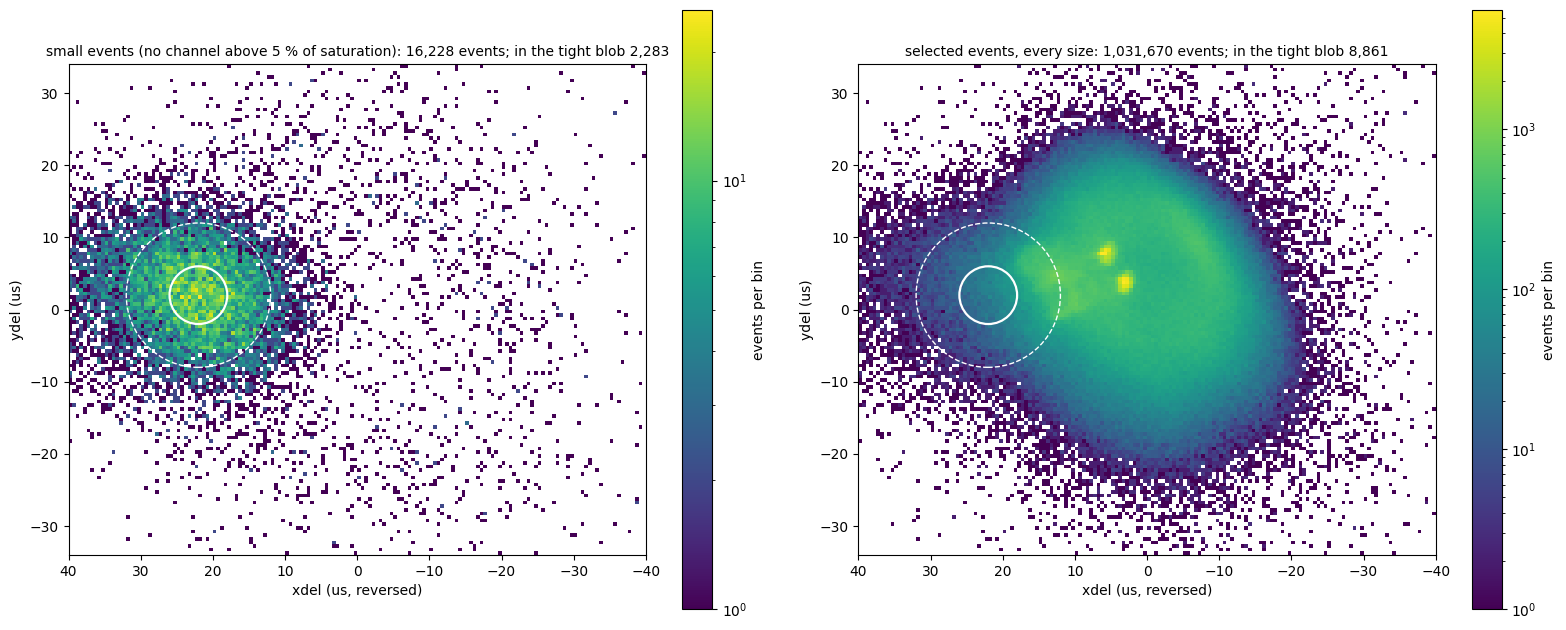

In [3]:
from matplotlib.patches import Circle
small_sel = use & small
fig, axes = plt.subplots(1, 2, figsize=(16, 6.4))
for ax, m, title in ((axes[0], small_sel, "small events (no channel above 5 % of saturation)"), (axes[1], use, "selected events, every size")):
    h = ax.hist2d(xdel[m], ydel[m], bins=[160, 136], range=[[-40, 40], [-34, 34]], cmap="viridis", norm=colors.LogNorm(), cmin=1)
    fig.colorbar(h[3], ax=ax, label="events per bin")
    ax.add_patch(Circle((BLOB_X, BLOB_Y), BLOB_R, fill=False, ec="w", lw=1.6))
    ax.add_patch(Circle((BLOB_X, BLOB_Y), BLOB_R_OUT, fill=False, ec="w", lw=1.0, ls="--"))
    ax.set_xlim(40, -40); ax.set_ylim(-34, 34); ax.set_aspect("equal")
    ax.set_xlabel("xdel (us, reversed)"); ax.set_ylabel("ydel (us)")
    ax.set_title(f"{title}: {m.sum():,} events; in the tight blob {(m & (r_blob < BLOB_R)).sum():,}", fontsize=10)
fig.tight_layout()
plt.show()

## The summed window integral

The window integral summed over the six channels, A to F, for the blob, for the other small, quiet events, and for the random triggers. The random triggers show where zero is and how wide the noise is. Counts per bin on a log vertical scale: the low end (the small pulses and the zero of the random triggers) and the full range.

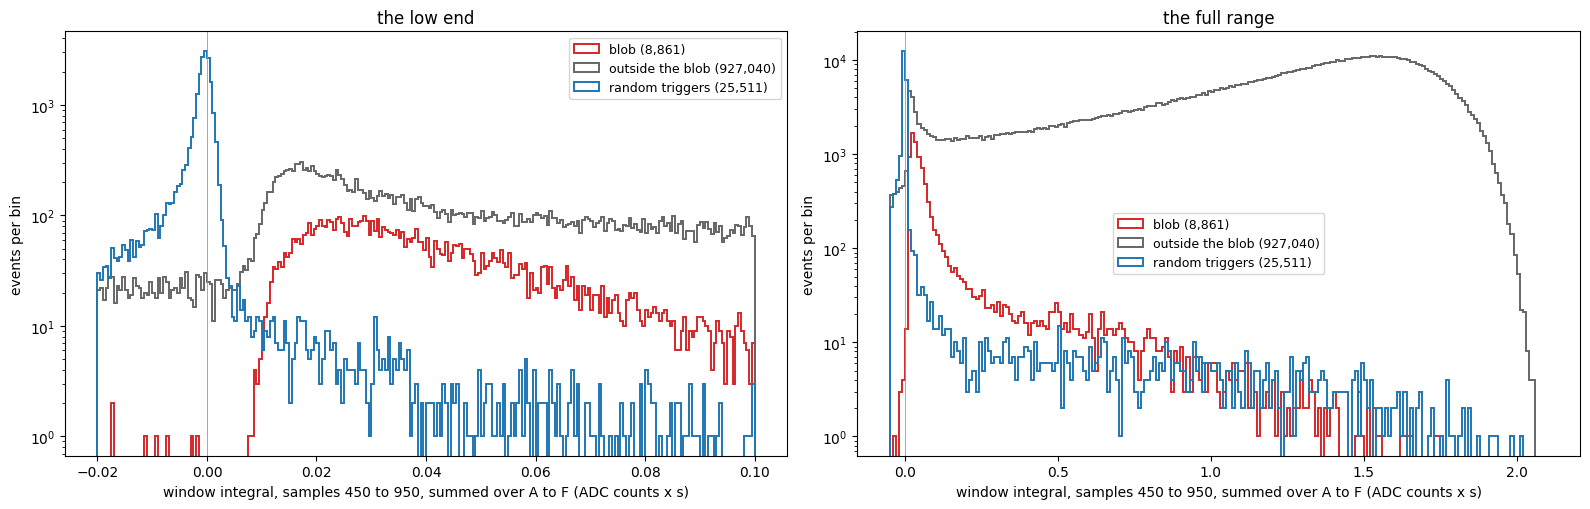

In [4]:
SETS = ((blob, "C3", f"blob ({blob.sum():,})"), (rest, "0.4", f"outside the blob ({rest.sum():,})"),
        (randoms, "C0", f"random triggers ({randoms.sum():,})"))
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
for ax, bins, zoom in ((axes[0], np.linspace(-0.02, 0.1, 241), True), (axes[1], np.linspace(-0.05, 2.1, 216), False)):
    for m, c, lab in SETS:
        ax.hist(wsum[m], bins=bins, histtype="step", color=c, linewidth=1.4, label=lab)
    ax.axvline(0, color="0.6", linewidth=0.6)
    ax.set_xlabel("window integral, samples 450 to 950, summed over A to F (ADC counts x s)")
    ax.set_ylabel("events per bin")
    ax.set_yscale("log")
    ax.set_title("the low end" if zoom else "the full range")
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

### All six channels against the inner four, and against Side2pF

The sum over the inner channels, C + D + E + F, and the Side2pF window integral, each plotted against the sum over all six. One pulse shape, shared the same way among the channels, would put the events on one line through the origin.

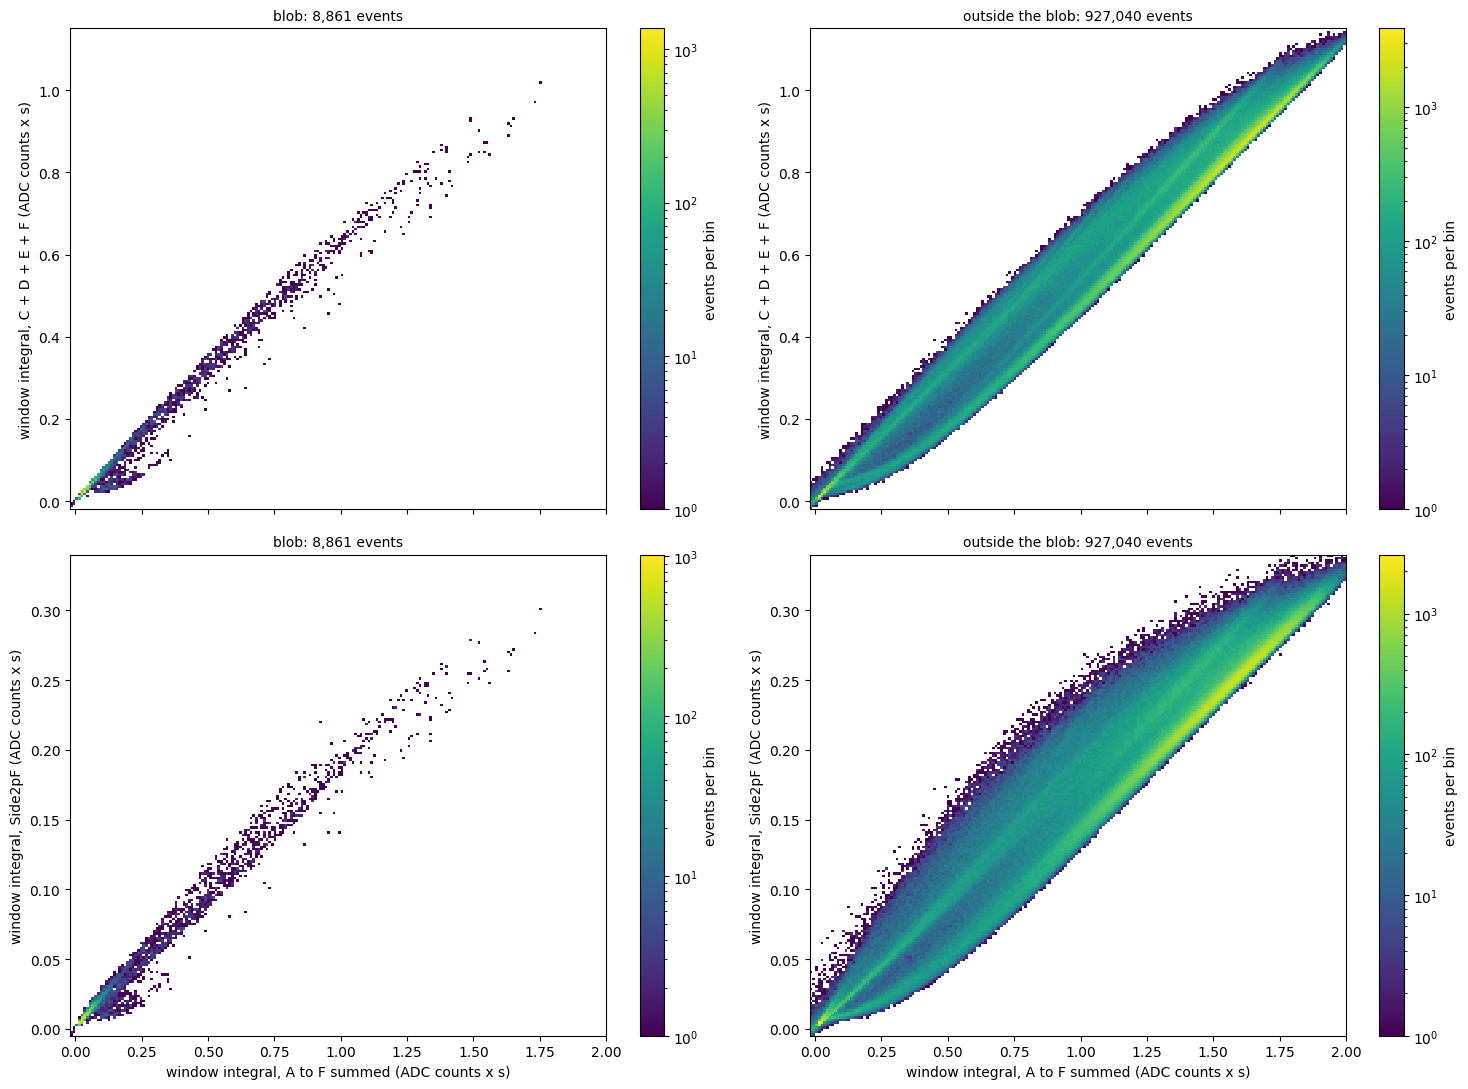

In [5]:
inner = wint[:, 2:].sum(axis=1)
fig, axes = plt.subplots(2, 2, figsize=(15, 11), sharex=True)
for col, (m, title) in enumerate(((blob, "blob"), (rest, "outside the blob"))):
    for row, (y, ylab, yr) in enumerate(((inner, "C + D + E + F", (-0.02, 1.15)), (wint[:, 5], "Side2pF", (-0.005, 0.34)))):
        ax = axes[row, col]
        h = ax.hist2d(wsum[m], y[m], bins=[200, 200], range=[(-0.02, 2.0), yr], cmap="viridis", norm=colors.LogNorm(), cmin=1)
        fig.colorbar(h[3], ax=ax, label="events per bin")
        ax.set_ylabel(f"window integral, {ylab} (ADC counts x s)")
        ax.set_title(f"{title}: {m.sum():,} events", fontsize=10)
for ax in axes[1]:
    ax.set_xlabel("window integral, A to F summed (ADC counts x s)")
fig.tight_layout()
plt.show()

### All the events, with the bstd cut only

The summed window integral of every real trigger that passes the `bstd` cut in all six channels, with the selected events drawn on the same axis: the difference between the two is what the cut on the times removes. The window ends 360 us after the trigger, while large pulses last milliseconds. For those events the window integral is therefore only the start of the pulse, and the fit of the line through the pulse lowers it.

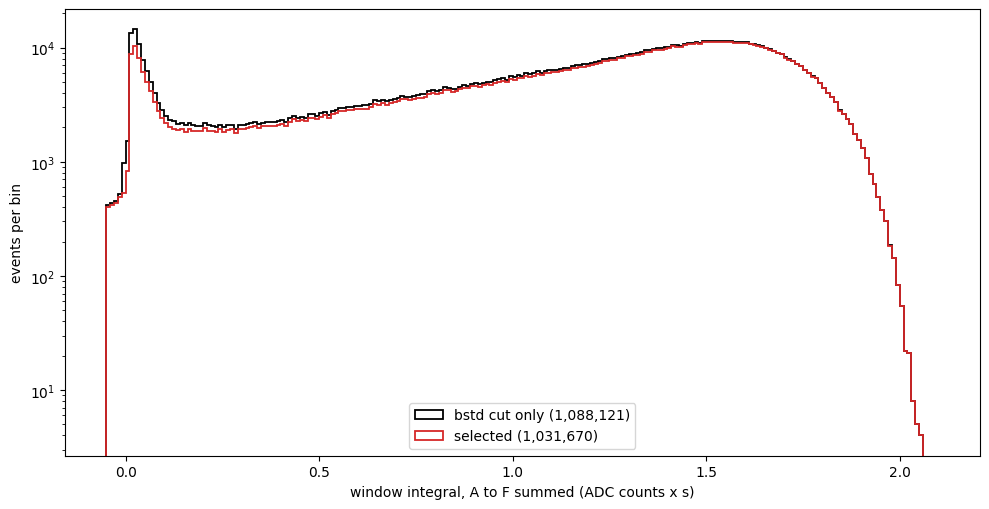

In [6]:
BINS_ALL = np.linspace(-0.05, 2.1, 216)
fig, ax = plt.subplots(figsize=(10, 5.2))
for m, c, lab in ((real & keep & bstd_ok, "k", f"bstd cut only ({(real & keep & bstd_ok).sum():,})"), (use, "C3", f"selected ({use.sum():,})")):
    ax.hist(wsum[m], bins=BINS_ALL, histtype="step", color=c, linewidth=1.3, label=lab)
ax.set_yscale("log")
ax.set_xlabel("window integral, A to F summed (ADC counts x s)")
ax.set_ylabel("events per bin")
ax.legend()
fig.tight_layout()
plt.show()

## The summed maximum height

The same cuts again, now with the pulse height: `current_max`, the largest value of the trace above its baseline, summed over the six channels. The heights come from the new dataset, `r76-82V-window-integral`, so they are taken after the line has been subtracted, the same traces the window integral uses. They are read once and cached next to the window integral (`relcal-height-82v.npz`).

The cut on the size, no channel above 5 % of saturation, uses the heights of the old dataset. The two differ a little: the new heights are about 5 % higher.

**A maximum is never zero:** on a trace with no pulse it picks the largest upward noise excursion. The random triggers therefore sit at a positive height, a few counts per channel, and their sum is not centred on zero, unlike the integral.

          selected: summed height 10/50/90 %:  1550.6   3975.2   5007.4 counts
              blob: summed height 10/50/90 %:   141.4    281.6   1782.7 counts
  outside the blob: summed height 10/50/90 %:  1999.9   4075.5   5033.0 counts
   random triggers: summed height 10/50/90 %:    42.2     55.6   2167.9 counts
random triggers, per channel, median height: A 7.2, B 11.3, C 6.2, D 11.0, E 6.2, F 6.4


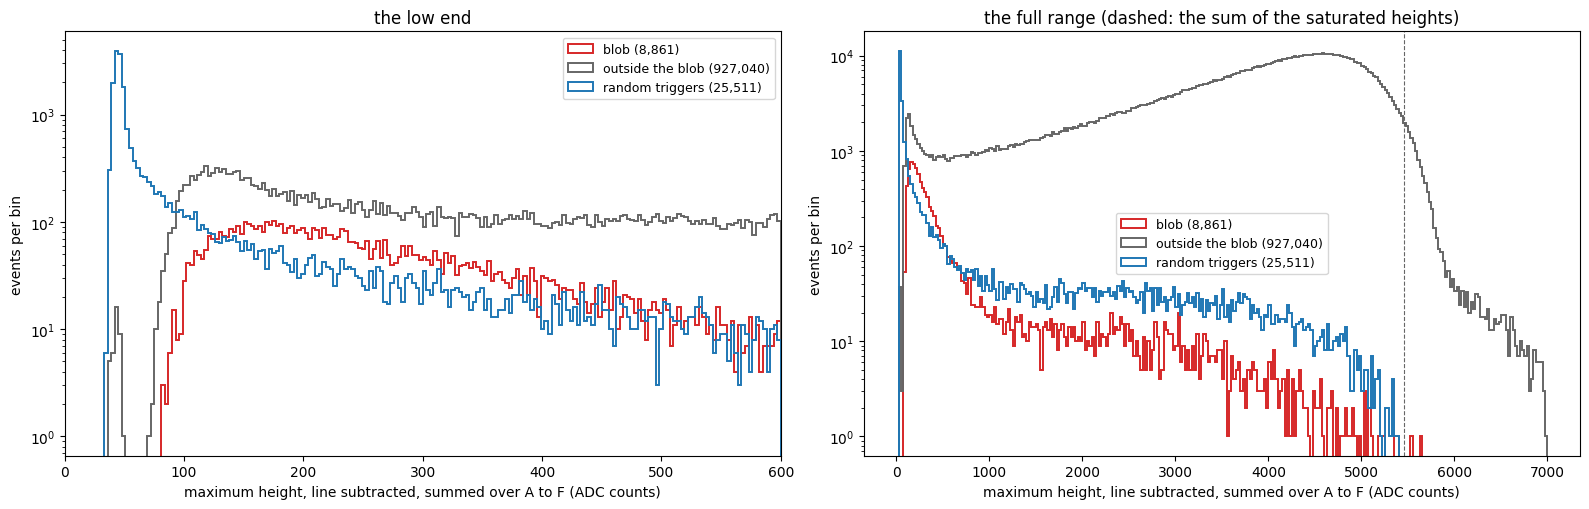

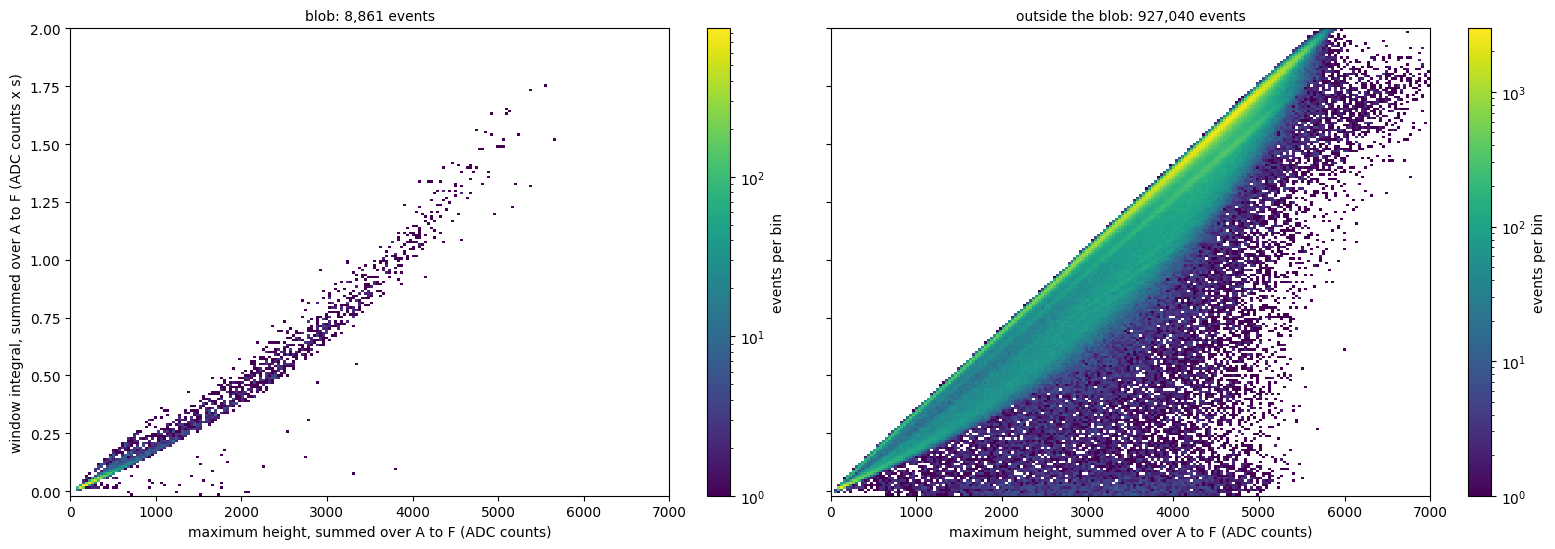

In [7]:
HCACHE = Path.home() / "goldsluice-output" / "relcal-height-82v.npz"
if HCACHE.exists():
    hwin = np.load(HCACHE)["hwin"]
else:
    hwin = np.vstack([np.column_stack([field(pq.read_table(f, columns=[f"Side2p{k}" for k in LETTERS]), k, "current_max") for k in LETTERS])
                      for f in files(OUT_WIN)])
    np.savez(HCACHE, hwin=hwin)
assert len(hwin) == len(series), "the height cache does not match: delete it and rerun"
hsum = hwin.sum(axis=1)                                     # ADC counts, all six channels
for name, m in (("selected", use), ("blob", blob), ("outside the blob", rest), ("random triggers", randoms)):
    p = np.percentile(hsum[m], [10, 50, 90])
    print(f"{name:>18}: summed height 10/50/90 %: " + "  ".join(f"{v:7.1f}" for v in p) + " counts")
print("random triggers, per channel, median height: " + ", ".join(f"{k} {v:.1f}" for k, v in zip(LETTERS, np.median(hwin[randoms], axis=0))))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
for ax, bins, zoom in ((axes[0], np.arange(0, 601, 3), True), (axes[1], np.arange(0, 7001, 25), False)):
    for m, c, lab in SETS:
        ax.hist(hsum[m], bins=bins, histtype="step", color=c, linewidth=1.4, label=lab)
    ax.axvline(SATH.sum(), color="0.4", ls="--", lw=0.8)
    ax.set_xlabel("maximum height, line subtracted, summed over A to F (ADC counts)")
    ax.set_ylabel("events per bin")
    ax.set_yscale("log")
    if zoom:
        ax.set_xlim(0, 600)
    ax.set_title("the low end" if zoom else "the full range (dashed: the sum of the saturated heights)")
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

# the summed height against the summed window integral
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), sharex=True, sharey=True)
for ax, (m, title) in zip(axes, ((blob, "blob"), (rest, "outside the blob"))):
    h = ax.hist2d(hsum[m], wsum[m], bins=[200, 200], range=[(0, 7000), (-0.02, 2.0)], cmap="viridis", norm=colors.LogNorm(), cmin=1)
    fig.colorbar(h[3], ax=ax, label="events per bin")
    ax.set_xlabel("maximum height, summed over A to F (ADC counts)")
    ax.set_title(f"{title}: {m.sum():,} events", fontsize=10)
axes[0].set_ylabel("window integral, summed over A to F (ADC counts x s)")
fig.tight_layout()
plt.show()

### All the events, with the bstd cut only

The summed height of every real trigger that passes the `bstd` cut in all six channels, with the selected events and the random triggers on the same axis. The sum of the saturated heights is 5,454 counts, marked by the dashed line.

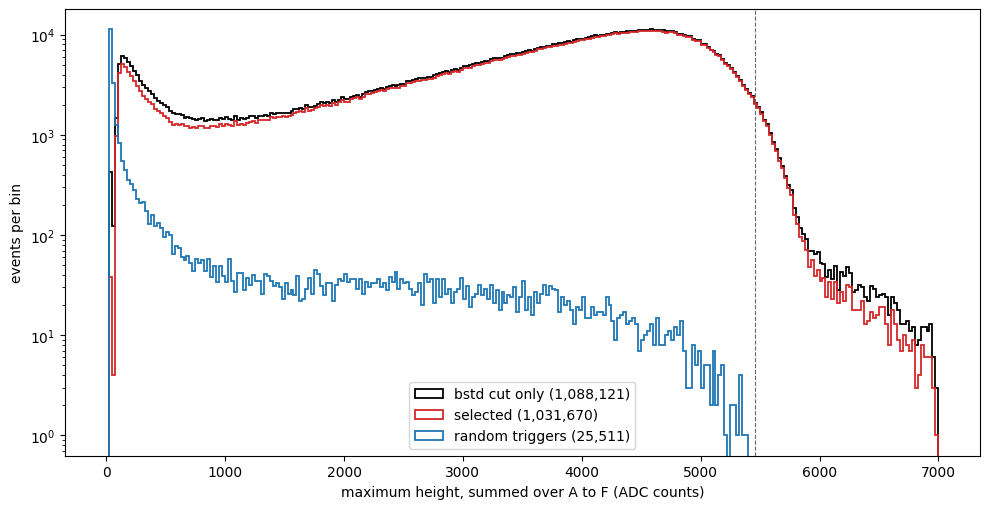

In [8]:
BINS_HA = np.arange(0, 7001, 25)
fig, ax = plt.subplots(figsize=(10, 5.2))
for m, c, lab in ((real & keep & bstd_ok, "k", f"bstd cut only ({(real & keep & bstd_ok).sum():,})"), (use, "C3", f"selected ({use.sum():,})"),
                  (randoms, "C0", f"random triggers ({randoms.sum():,})")):
    ax.hist(hsum[m], bins=BINS_HA, histtype="step", color=c, linewidth=1.3, label=lab)
ax.axvline(SATH.sum(), color="0.4", ls="--", lw=0.8)
ax.set_yscale("log")
ax.set_xlabel("maximum height, summed over A to F (ADC counts)")
ax.set_ylabel("events per bin")
ax.legend()
fig.tight_layout()
plt.show()